# Onde o faturamento vai crescer?
### Previsão do crescimento real do comércio varejista e dos serviços por estado

**Disciplina:** Mineração de Dados — trabalho do 2º bimestre · **Metodologia:** CRISP-DM

**Integrantes:** Jhonattan Curtarelli · _(adicionar os demais integrantes)_

<a href="https://colab.research.google.com/github/jhondev123/trabalho_mineracao_2bi/blob/main/trabalho_mineracao_dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

---

**O que este notebook faz:** parte dos **dados brutos**, exatamente como vieram das APIs do IBGE e do Banco Central, e
percorre as seis fases do CRISP-DM — limpeza e integração das fontes, criação de atributos e do alvo, exploração com
gráficos, treino de **dois modelos de aprendizado de máquina** (Regressão Logística e Random Forest), avaliação contra
uma regra simples e, no fim, o **ranking** dos estados com maior chance de crescer.

**Pergunta de negócio:** em quais estados o faturamento do varejo e dos serviços deve crescer **acima da inflação**
nos **próximos 3 meses**?

### Como rodar no Google Colab

1. No Google Drive, em **Meu Drive**, crie a pasta `trabalho_min_dados` e, dentro dela, a pasta `dados`.
2. Suba para `trabalho_min_dados/dados/` o arquivo `dados_brutos_20260914.xlsx` (está na pasta `dados/` do
   repositório no GitHub).
3. Abra este notebook no Colab (botão acima) e use **Ambiente de execução → Executar tudo**. Autorize o acesso ao
   Drive quando pedir.
4. Gráficos, tabelas e o modelo treinado são gravados em `trabalho_min_dados/saidas/`.

```
Meu Drive/
└── trabalho_min_dados/
    ├── dados/
    │   └── dados_brutos_20260914.xlsx   ← você sobe este arquivo
    └── saidas/                          ← o notebook cria
        ├── graficos/*.png
        ├── dataset_modelo.csv
        ├── metricas_teste.csv
        ├── ranking_previsao.csv
        └── modelo_final.joblib
```

Leva de 2 a 4 minutos; a parte mais demorada é a busca de parâmetros do Random Forest. Fora do Colab, o notebook lê a
pasta `dados/` ao lado dele.

### Roteiro

| Fase do CRISP-DM | Seção |
|---|---|
| 1. Entendimento do negócio | problema, alvo e critério de sucesso |
| 2. Entendimento dos dados | as 5 fontes, qualidade e primeiros gráficos |
| 3. Preparação dos dados | limpeza, integração, transformação, faltantes, divisão no tempo e desbalanceamento |
| 4. Modelagem | regra de comparação, Regressão Logística e Random Forest |
| 5. Avaliação | métricas no conjunto de teste, erros e importância dos atributos |
| 6. Implantação | modelo final, ranking de previsão e uso pela API |

## 0. Configuração

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn import __version__ as versao_sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Unknown solver options.*")  # aviso do SciPy com o scikit-learn 1.6
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

SEMENTE = 42  # fixa o sorteio do Random Forest: rodar de novo dá o mesmo resultado
print(f"pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {versao_sklearn} · seaborn {sns.__version__}")

pandas 2.2.2 · numpy 2.0.2 · scikit-learn 1.6.1 · seaborn 0.13.2


Pastas do projeto. No Colab, o Drive é montado em `/content/drive` e o notebook usa
`Meu Drive/trabalho_min_dados`. Para usar outra pasta, mude só `NOME_PASTA`.

In [2]:
NOME_PASTA = "trabalho_min_dados"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_BASE = Path("/content/drive/MyDrive") / NOME_PASTA
except ImportError:  # fora do Colab: usa a pasta onde o notebook está
    PASTA_BASE = Path.cwd()

PASTA_DADOS = PASTA_BASE / "dados"
PASTA_SAIDAS = PASTA_BASE / "saidas"
PASTA_GRAFICOS = PASTA_SAIDAS / "graficos"

arquivos = sorted(PASTA_DADOS.glob("dados_brutos_*.xlsx"))
if not arquivos:
    raise FileNotFoundError(
        f"Nenhum arquivo dados_brutos_*.xlsx em {PASTA_DADOS}. "
        "Suba o arquivo da pasta dados/ do repositório para essa pasta do Drive."
    )
ARQUIVO_BRUTO = arquivos[-1]  # se houver mais de um, usa a coleta mais recente
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

print("dados brutos:", ARQUIVO_BRUTO)
print("saídas:      ", PASTA_SAIDAS)

dados brutos: /content/trabalho_min_dados/dados/dados_brutos_20260914.xlsx
saídas:       /content/trabalho_min_dados/saidas


Estilo dos gráficos: cor só nas marcas (azul = varejo, laranja = serviços), texto e grade em cinza, um único eixo
por gráfico. Cada figura é salva em `saidas/graficos/` para usar no artigo.

In [3]:
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
VERMELHO, CINZA, NEUTRO = "#e34948", "#898781", "#f0efec"
TEXTO, TEXTO_2, GRADE, EIXO, FUNDO = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"

NOME_SETOR = {"COMERCIO_VAREJISTA": "Comércio varejista", "SERVICOS": "Serviços"}
COR_SETOR = {"COMERCIO_VAREJISTA": AZUL, "SERVICOS": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", [VERMELHO, NEUTRO, AZUL])
SEQUENCIAL = LinearSegmentedColormap.from_list("sequencial", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "font.size": 10, "axes.edgecolor": EIXO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TEXTO,
    "axes.labelcolor": TEXTO_2, "xtick.color": EIXO, "ytick.color": EIXO,
    "xtick.labelcolor": TEXTO_2, "ytick.labelcolor": TEXTO_2,
    "legend.frameon": False, "legend.labelcolor": TEXTO_2, "lines.linewidth": 1.8,
})


def salvar(fig, nome):
    fig.savefig(PASTA_GRAFICOS / nome, dpi=150, bbox_inches="tight")
    plt.show()

---
## 1. Entendimento do negócio

**Problema.** Quem decide onde abrir ou expandir um negócio, conceder crédito ou reforçar estoque precisa saber em
quais estados o consumo está ganhando força. O IBGE publica todo mês um índice de faturamento do comércio varejista e
dos serviços para cada estado, mas ele olha para trás: o que interessa é **antecipar** os próximos meses.

**Objetivo de mineração (classificação binária).** Para cada estado, setor e mês, prever:

> **alvo = 1** se o faturamento real (sem inflação) dos **3 meses seguintes** for **maior** que o dos mesmos 3 meses do
> ano anterior; **alvo = 0** se não.

- **Por que "real":** com a inflação, quase todo setor parece crescer. Descontar o IPCA mostra quem vendeu mais de
  verdade.
- **Por que comparar com os mesmos meses do ano anterior:** o Natal e outras datas se repetem todo ano
  (sazonalidade); comparar dezembro com dezembro cancela esse efeito.
- **Por que 3 meses:** o IBGE divulga com cerca de um mês e meio de atraso; 3 meses dá tempo de planejar sem ficar
  longe demais para prever.

**Critério de sucesso.** O modelo só agrega valor se acertar **mais que uma regra simples**: "se cresceu nos últimos 3
meses, vai crescer nos próximos 3" (`media_3m > 0`). Se não superar a regra, isso também é um resultado: significa
que a tendência recente já resume quase toda a informação disponível.

---
## 2. Entendimento dos dados

### 2.1 As fontes

O arquivo `dados_brutos_*.xlsx` tem uma aba por fonte, com os dados **exatamente como as APIs devolveram**, sem
nenhum tratamento (a coleta é feita pelos scripts da pasta `coleta/` do repositório).

| Aba | Fonte | O que mede | Recorte |
|---|---|---|---|
| IBGE varejo 8880 | IBGE — Pesquisa Mensal de Comércio (PMC) | índice de receita nominal do varejo (média de 2022 = 100), sem ajuste sazonal | Brasil + 27 UFs |
| IBGE serviços 5906 | IBGE — Pesquisa Mensal de Serviços (PMS) | índice de receita nominal dos serviços (média de 2022 = 100), sem ajuste sazonal | Brasil + 27 UFs |
| IBGE IPCA 1737 | IBGE — IPCA | número-índice da inflação oficial (dez/1993 = 100) | Brasil |
| BCB dólar 3698 | Banco Central — SGS | dólar comercial (venda), média do mês, R$/US$ | Brasil |
| BCB Selic 4189 | Banco Central — SGS | Selic do mês, % ao ano | Brasil |

**Por que um índice e não reais:** o IBGE não publica faturamento mensal em R$. O índice mostra quanto o faturamento
subiu ou caiu: 118,5 significa 18,5% acima da média mensal de 2022.

In [4]:
abas = pd.read_excel(ARQUIVO_BRUTO, sheet_name=None)  # dicionário: nome da aba -> DataFrame
print("abas:", list(abas))
abas["IBGE varejo 8880"].head()

abas: ['Leia-me', 'IBGE varejo 8880', 'IBGE serviços 5906', 'IBGE IPCA 1737', 'BCB dólar 3698', 'BCB Selic 4189']


,Id da variável,Variável,Unidade,Classificação,Categoria,Nível territorial,Código da localidade,Localidade,Período,Valor
0,7169,PMC - Número-índice (2022=100),Número-índice,Tipos de índice,Índice de receita nominal de vendas no comérci...,Brasil,1,Brasil,201201,45.30376
1,7169,PMC - Número-índice (2022=100),Número-índice,Tipos de índice,Índice de receita nominal de vendas no comérci...,Brasil,1,Brasil,201202,43.19865
2,7169,PMC - Número-índice (2022=100),Número-índice,Tipos de índice,Índice de receita nominal de vendas no comérci...,Brasil,1,Brasil,201203,47.62816
3,7169,PMC - Número-índice (2022=100),Número-índice,Tipos de índice,Índice de receita nominal de vendas no comérci...,Brasil,1,Brasil,201204,45.43533
4,7169,PMC - Número-índice (2022=100),Número-índice,Tipos de índice,Índice de receita nominal de vendas no comérci...,Brasil,1,Brasil,201205,47.58430


In [5]:
abas["BCB dólar 3698"].head()

,Data,Valor
0,01/01/2012,1.7897
1,01/02/2012,1.7184
2,01/03/2012,1.7953
3,01/04/2012,1.8548
4,01/05/2012,1.9860


### 2.2 Qualidade dos dados

Para cada fonte: quantas linhas, que meses cobre, quantas localidades, se há valores que não são números (o IBGE
usa símbolos como `X` = sigilo, `..` = não se aplica, `...` = não disponível) e se há linhas duplicadas.

In [6]:
def periodo_bcb(datas):
    """'01/04/2025' -> 202504"""
    data = pd.to_datetime(datas, format="%d/%m/%Y")
    return data.dt.year * 100 + data.dt.month


qualidade = []
for nome, aba in abas.items():
    if nome == "Leia-me":
        continue
    periodos = aba["Período"].astype(int) if "Período" in aba else periodo_bcb(aba["Data"])
    qualidade.append({
        "aba": nome,
        "linhas": len(aba),
        "colunas": aba.shape[1],
        "primeiro mês": periodos.min(),
        "último mês": periodos.max(),
        "localidades": aba["Localidade"].nunique() if "Localidade" in aba else 1,
        "valores não numéricos": pd.to_numeric(aba["Valor"], errors="coerce").isna().sum(),
        "linhas duplicadas": aba.duplicated().sum(),
    })
pd.DataFrame(qualidade).set_index("aba")

,linhas,colunas,primeiro mês,último mês,localidades,valores não numéricos,linhas duplicadas
aba,,,,,,,
IBGE varejo 8880,4872,10,201201,202606,28,0,0
IBGE serviços 5906,4900,10,201201,202607,28,0,0
IBGE IPCA 1737,176,8,201201,202608,1,0,0
BCB dólar 3698,176,2,201201,202608,1,0,0
BCB Selic 4189,177,2,201201,202609,1,0,0


In [7]:
# Estatísticas descritivas do valor publicado em cada fonte
pd.DataFrame({nome: aba["Valor"].describe() for nome, aba in abas.items() if nome != "Leia-me"}).round(2)

,IBGE varejo 8880,IBGE serviços 5906,IBGE IPCA 1737,BCB dólar 3698,BCB Selic 4189
count,4872.00,4900.00,176.00,176.00,177.00
mean,81.14,89.98,5372.78,4.04,9.92
std,25.09,20.82,1247.50,1.27,3.81
min,31.88,34.12,3422.79,1.72,1.90
25%,60.84,74.67,4364.25,3.14,6.72
50%,75.58,84.54,5210.36,3.99,10.65
75%,101.21,104.35,6482.67,5.22,13.65
max,173.41,180.71,7657.73,6.10,14.90


**O que a tabela mostra:**

- nenhuma fonte tem valores não numéricos nem linhas duplicadas nesta coleta — mesmo assim, a limpeza (seção 3.1)
  trata esses casos, porque uma coleta futura pode trazê-los;
- o varejo vai até **jun/2026** e os serviços até **jul/2026** (o IBGE publica os serviços antes);
- a Selic tem um mês a mais (**set/2026**, mês ainda em andamento na coleta). Esse mês não tem faturamento e sai
  sozinho na junção (seção 3.2);
- os índices de faturamento têm escalas próximas (média de 2022 = 100), mas o IPCA (~3.400 a ~7.500), o dólar
  (~1,7 a ~5,9) e a Selic (~2 a ~15) estão em escalas bem diferentes — isso importa para a Regressão Logística
  (seção 4).

### 2.3 Primeiros gráficos (dados brutos)

**Faturamento nominal do Brasil.** Tendência de alta, picos todo dezembro e a queda de abril/2020 (pandemia).

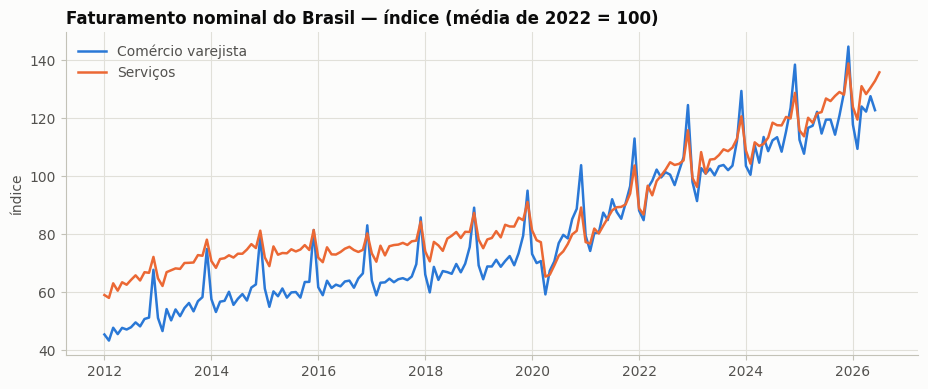

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for aba, setor in [("IBGE varejo 8880", "COMERCIO_VAREJISTA"), ("IBGE serviços 5906", "SERVICOS")]:
    brasil = abas[aba].query("Localidade == 'Brasil'")
    datas = pd.to_datetime(brasil["Período"].astype(str), format="%Y%m")
    ax.plot(datas, brasil["Valor"], color=COR_SETOR[setor], label=NOME_SETOR[setor])
ax.set_title("Faturamento nominal do Brasil — índice (média de 2022 = 100)")
ax.set_ylabel("índice")
ax.legend(loc="upper left")
salvar(fig, "01_brasil_nominal.png")

**Sazonalidade.** Quanto cada mês fatura acima ou abaixo da média do próprio ano, em todos os estados (2012–2025,
sem 2020). Dezembro do varejo fica bem acima da média (Natal) e fevereiro abaixo. É por isso que a comparação certa
é com o **mesmo mês do ano anterior**, e não com o mês anterior.

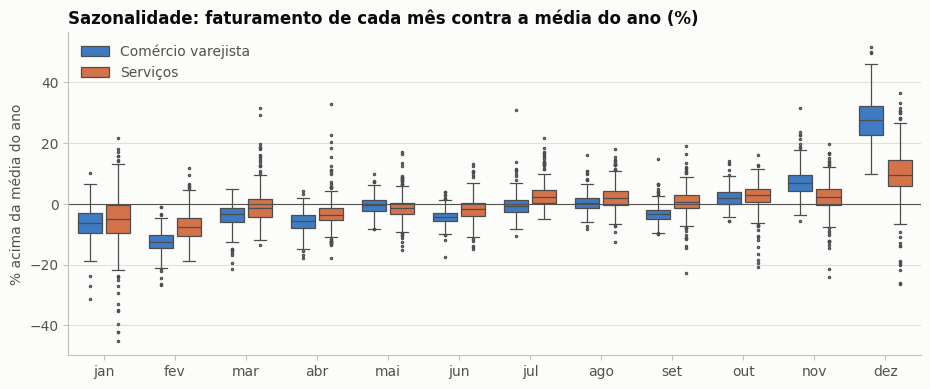

mes                  1     2    3    4    5    6    7    8    9    10   11    12
setor                                                                           
Comércio varejista -6.4 -12.6 -3.4 -5.7 -0.5 -4.4 -0.8  0.2 -3.5  1.9  6.9  27.4
Serviços           -5.2  -7.7 -1.6 -3.8 -1.4 -1.7  2.1  1.9  0.5  3.0  2.0   9.5


In [9]:
partes = []
for aba, setor in [("IBGE varejo 8880", "COMERCIO_VAREJISTA"), ("IBGE serviços 5906", "SERVICOS")]:
    d = abas[aba][["Localidade", "Período", "Valor"]].copy()
    d["ano"], d["mes"] = d["Período"] // 100, d["Período"] % 100
    d = d[d["ano"].between(2012, 2025) & (d["ano"] != 2020) & (d["Localidade"] != "Brasil")]
    media_do_ano = d.groupby(["Localidade", "ano"])["Valor"].transform("mean")
    d["acima_da_media"] = (d["Valor"] / media_do_ano - 1) * 100
    d["setor"] = NOME_SETOR[setor]
    partes.append(d)
sazonalidade = pd.concat(partes)

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=sazonalidade, x="mes", y="acima_da_media", hue="setor", palette=[AZUL, LARANJA],
            fliersize=1.5, linewidth=0.9, gap=0.15, ax=ax)
ax.axhline(0, color=TEXTO_2, linewidth=0.8)
ax.set_xticks(range(12), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_title("Sazonalidade: faturamento de cada mês contra a média do ano (%)")
ax.set_xlabel("")
ax.set_ylabel("% acima da média do ano")
ax.legend(title="", loc="upper left")
salvar(fig, "02_sazonalidade.png")

print(sazonalidade.groupby(["setor", "mes"])["acima_da_media"].median().unstack().round(1))

---
## 3. Preparação dos dados

Seis passos, cada um com o motivo:

| Passo | O que faz |
|---|---|
| 3.1 Seleção e limpeza | fica só com as colunas úteis, converte texto em número, descarta símbolos do IBGE, padroniza os estados |
| 3.2 Integração | junta as 5 fontes numa tabela única (uma linha por setor × estado × mês) |
| 3.3 Transformação | desconta a inflação e cria os 12 atributos, usando só o passado de cada mês |
| 3.4 Alvo | cria o que o modelo vai prever |
| 3.5 Dados faltantes | decide o que fazer com os valores vazios criados pelas janelas de tempo |
| 3.6 Divisão e desbalanceamento | separa treino, validação e teste por data e mede a proporção de cada classe |

### 3.1 Seleção e limpeza

Das 10 colunas das abas do IBGE, só três interessam: **localidade, período e valor** (as outras repetem o nome da
variável e da tabela em todas as linhas). O valor passa por `pd.to_numeric(errors="coerce")`: o que não for número
(símbolos do IBGE) vira vazio e é descartado. O nome do estado vira a sigla.

In [10]:
UF_SIGLA = {
    "Brasil": "BR", "Rondônia": "RO", "Acre": "AC", "Amazonas": "AM", "Roraima": "RR", "Pará": "PA",
    "Amapá": "AP", "Tocantins": "TO", "Maranhão": "MA", "Piauí": "PI", "Ceará": "CE",
    "Rio Grande do Norte": "RN", "Paraíba": "PB", "Pernambuco": "PE", "Alagoas": "AL", "Sergipe": "SE",
    "Bahia": "BA", "Minas Gerais": "MG", "Espírito Santo": "ES", "Rio de Janeiro": "RJ", "São Paulo": "SP",
    "Paraná": "PR", "Santa Catarina": "SC", "Rio Grande do Sul": "RS", "Mato Grosso do Sul": "MS",
    "Mato Grosso": "MT", "Goiás": "GO", "Distrito Federal": "DF",
}


def limpar_ibge(nome_aba, setor):
    bruto = abas[nome_aba]
    return pd.DataFrame({
        "setor": setor,
        "uf": bruto["Localidade"].map(UF_SIGLA),
        "periodo": bruto["Período"].astype(int),
        "indice_receita": pd.to_numeric(bruto["Valor"], errors="coerce"),  # símbolo do IBGE -> vazio
    })


faturamento = pd.concat([
    limpar_ibge("IBGE varejo 8880", "COMERCIO_VAREJISTA"),
    limpar_ibge("IBGE serviços 5906", "SERVICOS"),
], ignore_index=True)

print("linhas coletadas:            ", len(faturamento))
print("estados sem sigla:           ", faturamento["uf"].isna().sum())
print("valores não numéricos:       ", faturamento["indice_receita"].isna().sum())
faturamento = faturamento.dropna(subset=["uf", "indice_receita"])
print("duplicadas (setor, uf, mês): ", faturamento.duplicated(["setor", "uf", "periodo"]).sum())
faturamento = faturamento.drop_duplicates(["setor", "uf", "periodo"])
print("linhas após a limpeza:       ", len(faturamento))

linhas coletadas:             9772
estados sem sigla:            0
valores não numéricos:        0
duplicadas (setor, uf, mês):  0
linhas após a limpeza:        9772


**Meses seguidos.** Os atributos comparam cada mês com 12 meses antes, contando linhas. Isso só é correto se nenhuma
série tiver mês faltando — por isso a conferência abaixo.

In [11]:
faturamento = faturamento.sort_values(["setor", "uf", "periodo"]).reset_index(drop=True)
numero_do_mes = (faturamento["periodo"] // 100) * 12 + faturamento["periodo"] % 100
saltos = numero_do_mes.groupby([faturamento["setor"], faturamento["uf"]]).diff()
assert not (saltos > 1).any(), "há meses faltando em alguma série"

cobertura = faturamento.groupby("setor").agg(
    series=("uf", "nunique"), linhas=("periodo", "size"), primeiro_mes=("periodo", "min"), ultimo_mes=("periodo", "max")
)
print("nenhuma série com mês faltando")
cobertura

nenhuma série com mês faltando


,series,linhas,primeiro_mes,ultimo_mes
setor,,,,
COMERCIO_VAREJISTA,28,4872,201201,202606
SERVICOS,28,4900,201201,202607


### 3.2 Integração das fontes

IPCA, dólar e Selic são nacionais: o valor de cada mês é repetido em todas as linhas daquele mês. A junção é pela
coluna `periodo` (AAAAMM), com `how="left"` a partir do faturamento — por isso meses que só existem nos indicadores
(a Selic de set/2026) ficam de fora.

In [12]:
def limpar_bcb(nome_aba, coluna):
    bruto = abas[nome_aba]
    return pd.DataFrame({"periodo": periodo_bcb(bruto["Data"]), coluna: pd.to_numeric(bruto["Valor"], errors="coerce")})


ipca = pd.DataFrame({
    "periodo": abas["IBGE IPCA 1737"]["Período"].astype(int),
    "ipca": pd.to_numeric(abas["IBGE IPCA 1737"]["Valor"], errors="coerce"),
})
dolar = limpar_bcb("BCB dólar 3698", "dolar")
selic = limpar_bcb("BCB Selic 4189", "selic")

df = (faturamento
      .merge(ipca, on="periodo", how="left")
      .merge(dolar, on="periodo", how="left")
      .merge(selic, on="periodo", how="left"))
df["ano"], df["mes"] = df["periodo"] // 100, df["periodo"] % 100
df["data"] = pd.to_datetime(df["periodo"].astype(str), format="%Y%m")

print("meses só nos indicadores (ficam de fora):", sorted(set(selic["periodo"]) - set(df["periodo"])))
print("linhas da tabela integrada:", len(df), "| séries:", df.groupby(["setor", "uf"]).ngroups)
print("valores vazios após a junção:")
print(df[["indice_receita", "ipca", "dolar", "selic"]].isna().sum().to_string())
df.query("uf == 'SP' and setor == 'COMERCIO_VAREJISTA' and periodo in [202503, 202504]")

meses só nos indicadores (ficam de fora): [202608, 202609]
linhas da tabela integrada: 9772 | séries: 56
valores vazios após a junção:
indice_receita    0
ipca              0
dolar             0
selic             0


,setor,uf,periodo,indice_receita,ipca,dolar,selic,ano,mes,data
4682,COMERCIO_VAREJISTA,SP,202503,118.90037,7245.38,5.7468,13.57,2025,3,2025-03-01
4683,COMERCIO_VAREJISTA,SP,202504,118.53521,7276.54,5.7837,14.15,2025,4,2025-04-01


### 3.3 Transformação: inflação e atributos

**Descontar a inflação.** `indice_real = indice_receita ÷ ipca`, reescalado para a média de 2022 de cada série valer
100 (só para ficar legível — a escala não muda nenhuma variação). Divide-se, e não subtrai-se: crescimento real =
(1 + nominal) ÷ (1 + inflação) − 1.

**Atributos.** Cada atributo usa **só meses até o da própria linha**. Se usasse meses posteriores, o modelo
"veria o futuro" no treino (vazamento de dados) e erraria na vida real.

| Atributo | O que mostra | Conta |
|---|---|---|
| `var_anual_real` | crescimento real contra o mesmo mês do ano anterior (%) | `indice_real(t) ÷ indice_real(t−12) − 1` |
| `media_3m`, `media_6m`, `media_12m` | tendência recente desse crescimento | média móvel de 3, 6 e 12 meses |
| `aceleracao` | acelerando (+) ou freando (−) | `media_3m − media_12m` |
| `oscilacao_12m` | instabilidade no último ano | desvio-padrão de 12 meses |
| `var_anual_real_br` | o mesmo setor no Brasil | `var_anual_real` da linha BR |
| `ipca_12m` | inflação em 12 meses (%) | `ipca(t) ÷ ipca(t−12) − 1` |
| `selic`, `selic_var_12m` | juros e a mudança em 12 meses (pp) | `selic(t)`, `selic(t) − selic(t−12)` |
| `dolar_var_12m` | variação do dólar em 12 meses (%) | `dolar(t) ÷ dolar(t−12) − 1` |
| `pandemia` | período fora do padrão | 1 de mar/2020 a dez/2021 |

In [13]:
ATRIBUTOS = [
    "var_anual_real", "media_3m", "media_6m", "media_12m", "aceleracao", "oscilacao_12m",
    "var_anual_real_br", "ipca_12m", "selic", "selic_var_12m", "dolar_var_12m", "pandemia",
]
CHAVE = ["setor", "uf"]

# 1) inflação descontada, média de 2022 = 100 em cada série
real = df["indice_receita"] / df["ipca"]
base_2022 = real[df["ano"] == 2022].groupby([df["setor"], df["uf"]]).mean().rename("base_2022")
df = df.join(base_2022, on=CHAVE)
df["indice_real"] = real / df["base_2022"] * 100
df = df.drop(columns="base_2022")

# 2) crescimento real contra o mesmo mês do ano anterior (tira a sazonalidade)
serie = df.groupby(CHAVE, sort=False)
df["var_anual_real"] = (df["indice_real"] / serie["indice_real"].shift(12) - 1) * 100

# 3) tendência, aceleração e oscilação (janelas que terminam no mês da linha)
variacao = df.groupby(CHAVE, sort=False)["var_anual_real"]
for meses in (3, 6, 12):
    df[f"media_{meses}m"] = variacao.transform(lambda s: s.rolling(meses).mean())
df["aceleracao"] = df["media_3m"] - df["media_12m"]
df["oscilacao_12m"] = variacao.transform(lambda s: s.rolling(12).std())

# 4) o mesmo setor no Brasil, no mesmo mês
brasil = df[df["uf"] == "BR"].set_index(["setor", "periodo"])["var_anual_real"].rename("var_anual_real_br")
df = df.join(brasil, on=["setor", "periodo"])

# 5) cenário da economia (uma linha por mês, depois repetida em todas as séries)
macro = df[["periodo", "ipca", "dolar", "selic"]].drop_duplicates("periodo").set_index("periodo").sort_index()
macro["ipca_12m"] = (macro["ipca"] / macro["ipca"].shift(12) - 1) * 100
macro["selic_var_12m"] = macro["selic"] - macro["selic"].shift(12)
macro["dolar_var_12m"] = (macro["dolar"] / macro["dolar"].shift(12) - 1) * 100
df = df.join(macro[["ipca_12m", "selic_var_12m", "dolar_var_12m"]], on="periodo")

# 6) marca da pandemia
df["pandemia"] = df["periodo"].between(202003, 202112).astype(int)

df.query("uf == 'SP' and setor == 'COMERCIO_VAREJISTA' and periodo == 202504")[["indice_real"] + ATRIBUTOS].round(2)

,indice_real,var_anual_real,media_3m,media_6m,media_12m,aceleracao,oscilacao_12m,var_anual_real_br,ipca_12m,selic,selic_var_12m,dolar_var_12m,pandemia
4683,103.84,7.84,3.09,3.46,3.97,-0.88,2.31,6.31,5.53,14.15,3.5,12.76,0


**Nominal × real.** Com a inflação, o varejo do Brasil parece ter mais que dobrado desde 2012; sem ela, o
crescimento é bem menor. É o faturamento real que o modelo vai prever.

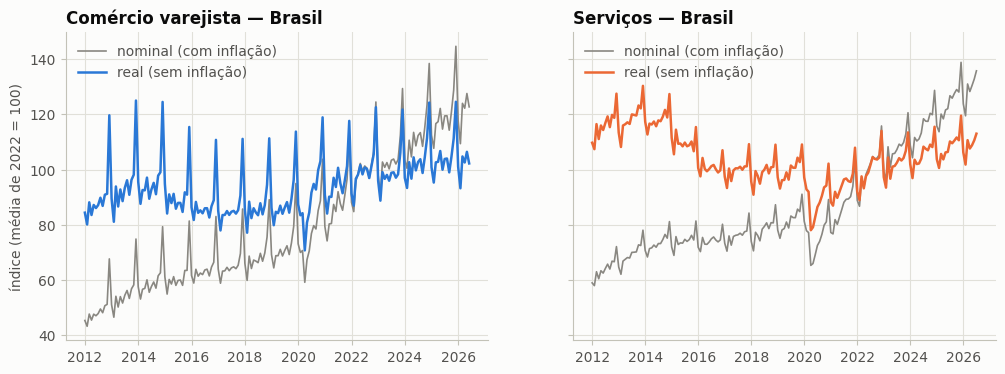

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, setor in zip(eixos, NOME_SETOR):
    brasil = df.query("uf == 'BR' and setor == @setor")
    ax.plot(brasil["data"], brasil["indice_receita"], color=CINZA, linewidth=1.2, label="nominal (com inflação)")
    ax.plot(brasil["data"], brasil["indice_real"], color=COR_SETOR[setor], label="real (sem inflação)")
    ax.set_title(f"{NOME_SETOR[setor]} — Brasil")
    ax.legend(loc="upper left")
eixos[0].set_ylabel("índice (média de 2022 = 100)")
salvar(fig, "03_nominal_vs_real.png")

**Crescimento real ano a ano, por estado.** Vermelho = o faturamento real caiu contra o ano anterior; azul = subiu.
As crises de 2015–16 e de 2020 aparecem em quase todos os estados ao mesmo tempo — o cenário nacional pesa, e por
isso entram atributos do Brasil e da economia.

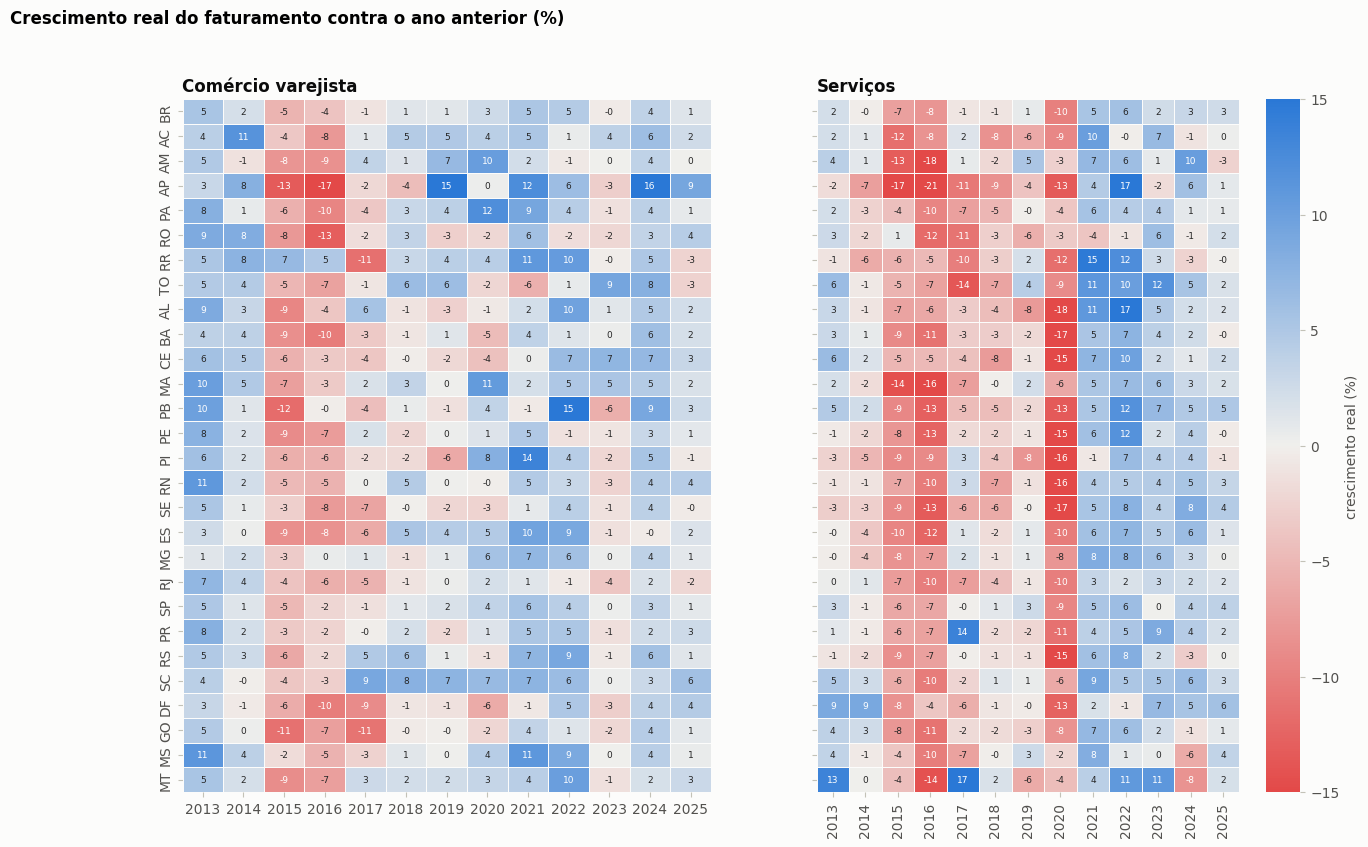

In [15]:
ORDEM_UF = ["BR", "AC", "AM", "AP", "PA", "RO", "RR", "TO", "AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE",
            "ES", "MG", "RJ", "SP", "PR", "RS", "SC", "DF", "GO", "MS", "MT"]

anual = df[df["ano"].between(2012, 2025)].groupby(["setor", "uf", "ano"])["indice_real"].sum()
cresc_anual = (anual.groupby(level=CHAVE).pct_change() * 100).dropna().rename("cresc_real").reset_index()

fig, eixos = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
for ax, setor in zip(eixos, NOME_SETOR):
    tabela = cresc_anual.query("setor == @setor").pivot(index="uf", columns="ano", values="cresc_real").loc[ORDEM_UF]
    sns.heatmap(tabela, cmap=DIVERGENTE, center=0, vmin=-15, vmax=15, annot=True, fmt=".0f",
                annot_kws={"fontsize": 6.5}, linewidths=0.5, linecolor=FUNDO, cbar=ax is eixos[-1],
                cbar_kws={"label": "crescimento real (%)"}, ax=ax)
    ax.set_title(NOME_SETOR[setor])
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Crescimento real do faturamento contra o ano anterior (%)", x=0.01, ha="left", fontweight="bold")
salvar(fig, "04_mapa_calor_crescimento_real.png")

### 3.4 Alvo

`cresc_real_prox_3m` = soma do `indice_real` de t+1 a t+3 ÷ soma de t−11 a t−9 − 1 (os mesmos meses, um ano antes).
`alvo = 1` se for maior que zero. É a única coluna que olha para o futuro — **nunca** entra como atributo.

In [16]:
real = df.groupby(CHAVE, sort=False)["indice_real"]
proximos_3m = real.shift(-1) + real.shift(-2) + real.shift(-3)
mesmos_meses_ano_anterior = real.shift(11) + real.shift(10) + real.shift(9)
df["cresc_real_prox_3m"] = (proximos_3m / mesmos_meses_ano_anterior - 1) * 100
df["alvo"] = (df["cresc_real_prox_3m"] > 0).astype(float).where(df["cresc_real_prox_3m"].notna())

# Conferência à mão: varejo de SP, abril/2025
sp = df.query("uf == 'SP' and setor == 'COMERCIO_VAREJISTA'").set_index("periodo")["indice_real"]
conta = (sp[[202505, 202506, 202507]].sum() / sp[[202405, 202406, 202407]].sum() - 1) * 100
linha = df.query("uf == 'SP' and setor == 'COMERCIO_VAREJISTA' and periodo == 202504").iloc[0]
print(f"SP varejo abr/2025: maio–jul/2025 contra maio–jul/2024 = {conta:+.2f}% (no dataset: "
      f"{linha['cresc_real_prox_3m']:+.2f}%) -> alvo {int(linha['alvo'])}")

SP varejo abr/2025: maio–jul/2025 contra maio–jul/2024 = +1.09% (no dataset: +1.09%) -> alvo 1


### 3.5 Tratamento de dados faltantes

As fontes não têm meses faltando, mas as **janelas de tempo** criam valores vazios:

- no **começo** de cada série, não há 12 meses anteriores para `var_anual_real`, nem 12 valores dela para
  `media_12m` e `oscilacao_12m` (os primeiros 23 meses ficam incompletos);
- no **fim**, os 3 últimos meses ainda não têm os 3 meses seguintes, então o alvo fica vazio.

In [17]:
faltantes = df[ATRIBUTOS + ["alvo"]].isna().sum().to_frame("valores vazios")
faltantes["% das linhas"] = (faltantes["valores vazios"] / len(df) * 100).round(1)
faltantes.T

,var_anual_real,media_3m,media_6m,media_12m,aceleracao,oscilacao_12m,var_anual_real_br,ipca_12m,selic,selic_var_12m,dolar_var_12m,pandemia,alvo
valores vazios,672.0,784.0,952.0,1288.0,1288.0,1288.0,672.0,672.0,0.0,672.0,672.0,0.0,784.0
% das linhas,6.9,8.0,9.7,13.2,13.2,13.2,6.9,6.9,0.0,6.9,6.9,0.0,8.0


**Decisão: não preencher (imputar), e sim separar.**

- **Começo das séries** (dez/2013 para trás): as linhas sem atributos são **removidas**. Preencher com média ou com
  zero inventaria um crescimento que não aconteceu, e são só os primeiros 23 meses de cada série (2012–2013).
- **Fim das séries:** as linhas sem alvo **não** são descartadas — viram o conjunto de **previsão**, que é justamente
  o que o modelo final vai responder (seção 6).
- **Linhas do Brasil (BR):** saem do modelo, porque já viraram o atributo `var_anual_real_br`.

In [18]:
meses_ate_fim_do_alvo = df["ano"] * 12 + df["mes"] - 1 + 3  # último mês que o alvo usa (t+3)
fim_do_alvo = (meses_ate_fim_do_alvo // 12) * 100 + meses_ate_fim_do_alvo % 12 + 1

df["conjunto"] = "teste"
df.loc[fim_do_alvo <= 202312, "conjunto"] = "validacao"
df.loc[fim_do_alvo <= 202212, "conjunto"] = "treino"
df.loc[df["alvo"].isna(), "conjunto"] = "previsao"

modelo = df[df["uf"] != "BR"].dropna(subset=ATRIBUTOS).copy()
print(f"linhas antes: {len(df)} | removidas (Brasil ou começo da série): {len(df) - len(modelo)} | "
      f"dataset do modelo: {len(modelo)} linhas, {modelo.groupby(CHAVE).ngroups} séries")
print("atributos vazios no dataset do modelo:", int(modelo[ATRIBUTOS].isna().sum().sum()))

linhas antes: 9772 | removidas (Brasil ou começo da série): 1591 | dataset do modelo: 8181 linhas, 54 séries
atributos vazios no dataset do modelo: 0


### 3.6 Divisão no tempo e desbalanceamento

**Divisão por data, nunca sorteada.** Em séries temporais, sortear linhas para o teste deixaria o modelo aprender com
meses posteriores aos que ele vai prever. A divisão usa o **último mês que o alvo consulta** (t+3), para nenhum dado
de validação ou de teste ajudar o treino:

| Conjunto | Regra | Para quê |
|---|---|---|
| treino | alvo termina até dez/2022 | o modelo aprende |
| validação | alvo termina em 2023 | escolher os parâmetros e comparar variações |
| teste | alvo termina depois de 2023 | avaliação final, usada **uma única vez** |
| previsão | ainda sem alvo | o ranking final |

In [19]:
divisao = modelo.groupby("conjunto").agg(
    linhas=("alvo", "size"), casos_de_alta=("alvo", "sum"), pct_alta=("alvo", "mean"),
    primeiro_mes=("periodo", "min"), ultimo_mes=("periodo", "max"),
).reindex(["treino", "validacao", "teste", "previsao"])
divisao["pct_alta"] = (divisao["pct_alta"] * 100).round(1)
divisao

,linhas,casos_de_alta,pct_alta,primeiro_mes,ultimo_mes
conjunto,,,,,
treino,5724,2420.0,42.3,201312,202209
validacao,648,414.0,63.9,202210,202309
teste,1647,1266.0,76.9,202310,202604
previsao,162,0.0,NaN,202604,202607


**Desbalanceamento.** A proporção de casos de alta **muda com o tempo**: 42% no treino (que inclui as crises de
2015–16 e 2020) e 77% no teste (2024–2026, anos de crescimento). Isso tem duas consequências:

1. **acurácia sozinha engana:** no teste, um "modelo" que responde sempre "vai crescer" acerta 77%. Por isso a métrica
   principal é a **acurácia balanceada** (média do acerto em cada classe), que dá 50% para esse chute;
2. o modelo é treinado num mundo mais pessimista que o do teste. O peso por classe (`class_weight="balanced"`) entra
   como opção na busca de parâmetros (seção 4), e o modelo final é re-treinado incluindo os anos mais recentes.

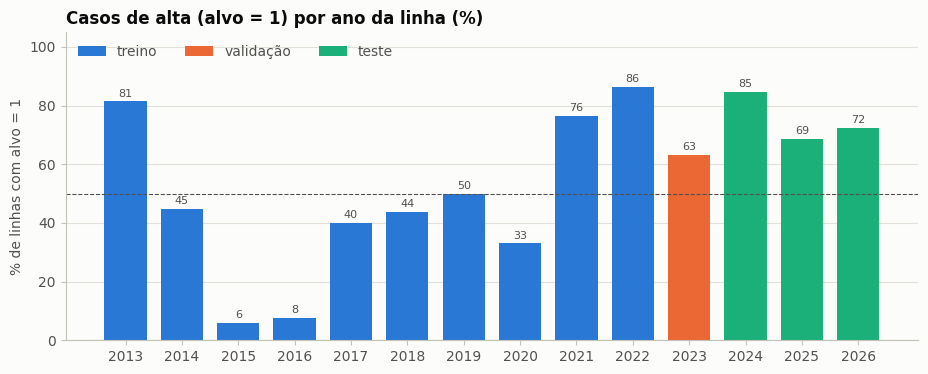

ano,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
pct_alta,81.5,44.9,6.0,7.7,40.1,43.8,50.0,33.0,76.4,86.4,63.1,84.6,68.7,72.5
linhas,54,648,648,648,648,648,648,648,648,648,648,648,648,189
conjunto,treino,treino,treino,treino,treino,treino,treino,treino,treino,treino,validacao,teste,teste,teste


In [20]:
por_ano = modelo.dropna(subset=["alvo"]).groupby("ano").agg(
    pct_alta=("alvo", "mean"), linhas=("alvo", "size"), conjunto=("conjunto", lambda s: s.mode()[0]))
por_ano["pct_alta"] *= 100

fig, ax = plt.subplots(figsize=(11, 4))
cores = {"treino": AZUL, "validacao": LARANJA, "teste": VERDE_AGUA}
for conjunto, cor in cores.items():
    parte = por_ano[por_ano["conjunto"] == conjunto]
    barras = ax.bar(parte.index, parte["pct_alta"], color=cor, width=0.75, label=conjunto.replace("validacao", "validação"))
    ax.bar_label(barras, fmt="%.0f", padding=2, fontsize=8, color=TEXTO_2)
ax.axhline(50, color=TEXTO_2, linewidth=0.8, linestyle="--")
ax.set_xticks(por_ano.index)
ax.set_ylim(0, 105)
ax.set_title("Casos de alta (alvo = 1) por ano da linha (%)")
ax.set_ylabel("% de linhas com alvo = 1")
ax.legend(loc="upper left", ncols=3)
ax.grid(axis="x", visible=False)
salvar(fig, "05_casos_de_alta_por_ano.png")
por_ano.round(1).T

Os anos de transição (2022 e 2023) têm linhas de dois conjuntos, porque a divisão é pelo mês em que o alvo termina;
no gráfico, cada ano tem a cor do conjunto da maior parte das suas linhas.

### 3.7 Exploração dos atributos

**Correlação.** Quanto cada par de atributos anda junto (−1 a 1). A última linha mostra a relação de cada atributo
com o crescimento dos próximos 3 meses (`cresc_real_prox_3m`). As médias de crescimento são muito parecidas entre si
— informação redundante, que o Random Forest lida bem e a Regressão Logística controla com regularização.

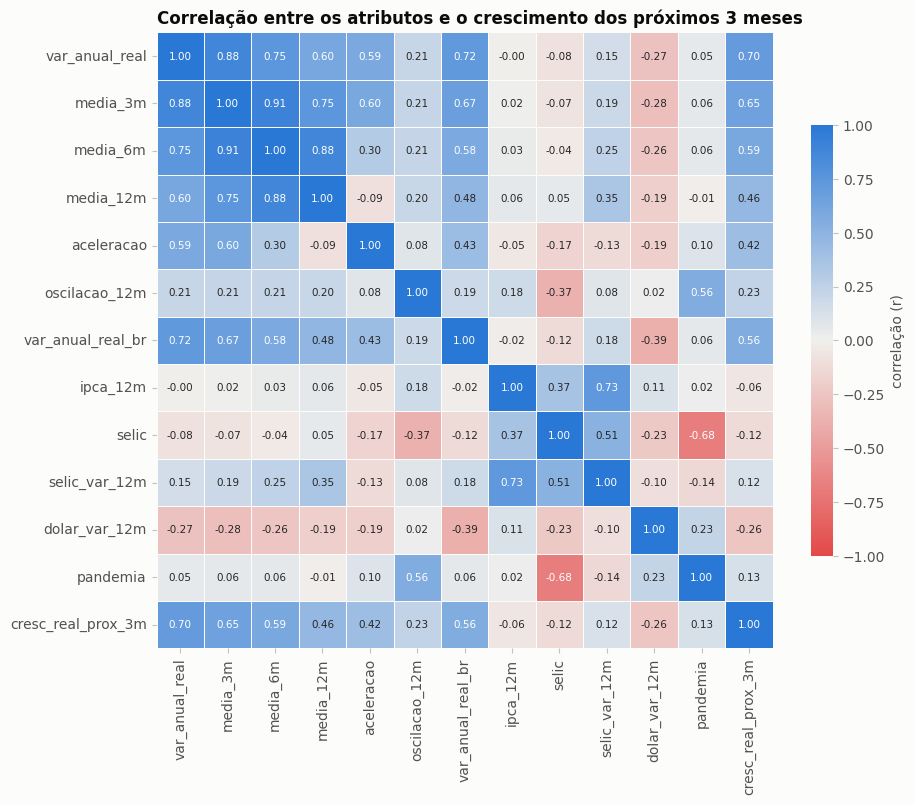

correlação com cresc_real_prox_3m:
var_anual_real       0.70
media_3m             0.65
media_6m             0.59
var_anual_real_br    0.56
media_12m            0.46
aceleracao           0.42
oscilacao_12m        0.23
pandemia             0.13
selic_var_12m        0.12
ipca_12m            -0.06
selic               -0.12
dolar_var_12m       -0.26


In [21]:
correlacao = modelo.dropna(subset=["alvo"])[ATRIBUTOS + ["cresc_real_prox_3m"]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlacao, cmap=DIVERGENTE, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"fontsize": 7.5}, linewidths=0.5, linecolor=FUNDO, square=True,
            cbar_kws={"label": "correlação (r)", "shrink": 0.7}, ax=ax)
ax.set_title("Correlação entre os atributos e o crescimento dos próximos 3 meses")
salvar(fig, "06_correlacao_atributos.png")

print("correlação com cresc_real_prox_3m:")
print(correlacao["cresc_real_prox_3m"].drop("cresc_real_prox_3m").sort_values(ascending=False).round(2).to_string())

**O atributo mais forte.** Quando a média dos últimos 3 meses (`media_3m`) é positiva, os 3 meses seguintes tendem a
crescer — é a lógica da regra de comparação. Mas as caixas se sobrepõem: há muitos casos em que a tendência vira.

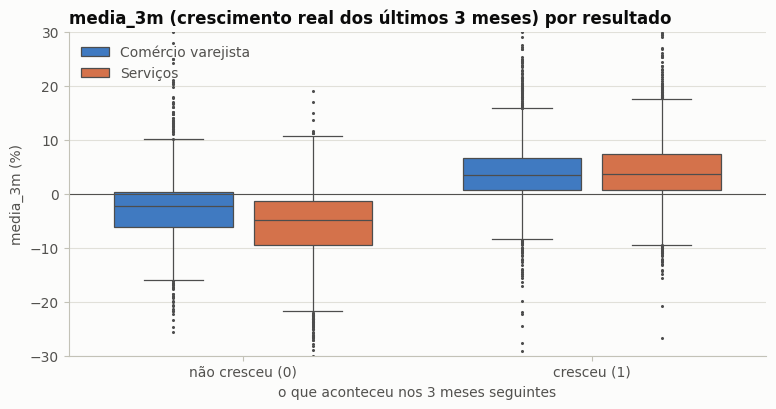

In [22]:
com_alvo = modelo.dropna(subset=["alvo"]).assign(
    resultado=lambda d: d["alvo"].map({0: "não cresceu (0)", 1: "cresceu (1)"}),
    setor_nome=lambda d: d["setor"].map(NOME_SETOR),
)
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=com_alvo, x="resultado", y="media_3m", hue="setor_nome", palette=[AZUL, LARANJA],
            order=["não cresceu (0)", "cresceu (1)"], fliersize=1.2, linewidth=0.9, gap=0.15, ax=ax)
ax.axhline(0, color=TEXTO_2, linewidth=0.8)
ax.set_ylim(-30, 30)
ax.set_title("media_3m (crescimento real dos últimos 3 meses) por resultado")
ax.set_xlabel("o que aconteceu nos 3 meses seguintes")
ax.set_ylabel("media_3m (%)")
ax.legend(title="", loc="upper left")
salvar(fig, "07_media_3m_por_alvo.png")

In [23]:
# Dataset preparado, salvo para o artigo e para quem quiser conferir no Excel (; e decimal ,)
COLUNAS_SAIDA = ["setor", "uf", "ano", "mes", "indice_receita", "ipca", "dolar", "selic", "indice_real"] + ATRIBUTOS + [
    "cresc_real_prox_3m", "alvo", "conjunto"]
modelo[COLUNAS_SAIDA].round(4).to_csv(PASTA_SAIDAS / "dataset_modelo.csv", index=False, sep=";", decimal=",",
                                       encoding="utf-8-sig")
print("salvo:", PASTA_SAIDAS / "dataset_modelo.csv")

salvo: /content/trabalho_min_dados/saidas/dataset_modelo.csv


---
## 4. Modelagem

### 4.1 O que entra no modelo

- **Atributos:** os 12 da seção 3.3 mais o **setor** (varejo ou serviços, convertido em uma coluna 0/1 com
  *one-hot encoding*). O **estado** não entra como atributo: seriam 27 colunas a mais para ~150 meses por série, com
  risco de o modelo decorar cada estado em vez de aprender o padrão — a seção 4.5 testa isso.
- **Alvo:** `alvo` (0 ou 1).

### 4.2 Referências de comparação (não são aprendizado de máquina)

- **Regra simples:** prever 1 quando `media_3m > 0`. É o critério de sucesso da fase 1.
- **Sempre alta:** prever 1 sempre. Mostra quanto se acerta "de graça" quando a maioria dos casos é de alta.

### 4.3 Os dois modelos

| | **Regressão Logística** | **Random Forest** |
|---|---|---|
| Como decide | soma ponderada dos atributos, transformada em probabilidade (curva sigmoide) | centenas de árvores de decisão, cada uma treinada com um sorteio das linhas e dos atributos; a resposta é a votação |
| Por que foi escolhido | simples, rápido e **interpretável**: o sinal de cada peso mostra se o atributo aumenta ou diminui a chance de alta | capta relações **não lineares** e combinações (ex.: juro alto pesa mais quando a tendência já está fraca), não precisa de padronização e mostra a importância de cada atributo |
| Cuidado necessário | atributos em escalas diferentes (Selic em %, dólar em %, pandemia 0/1) → **padronização** com `StandardScaler` (média 0, desvio 1) | pode decorar o treino (*overfitting*) → limitar a profundidade e o tamanho mínimo das folhas |
| Parâmetros testados | `C` (força da regularização: menor = pesos menores, modelo mais simples) e `class_weight` | `max_depth`, `min_samples_leaf` e `class_weight` |

Os dois devolvem uma **probabilidade** de alta, não só sim ou não — útil para o ranking.

### 4.4 Como os parâmetros são escolhidos

`GridSearchCV` testa todas as combinações de parâmetros. Com `PredefinedSplit`, cada combinação é **treinada no
treino e medida na validação** (2023), sem sorteio. A métrica de escolha é a **acurácia balanceada**. Escolhida a
melhor combinação, o modelo é re-treinado com treino + validação (`refit=True`), para aproveitar os meses mais
recentes. O conjunto de teste só é usado na fase 5.

In [24]:
ATRIBUTOS_MODELO = ATRIBUTOS + ["setor"]

treino = modelo[modelo["conjunto"] == "treino"]
validacao = modelo[modelo["conjunto"] == "validacao"]
teste = modelo[modelo["conjunto"] == "teste"]
previsao = modelo[modelo["conjunto"] == "previsao"]

treino_validacao = pd.concat([treino, validacao])
X_tv, y_tv = treino_validacao[ATRIBUTOS_MODELO], treino_validacao["alvo"].astype(int)
X_teste, y_teste = teste[ATRIBUTOS_MODELO], teste["alvo"].astype(int)

# -1 = linha usada só para treinar; 0 = linha da validação
divisao_validacao = PredefinedSplit(np.where(treino_validacao["conjunto"] == "treino", -1, 0))


def preparo(padronizar, categoricos=("setor",)):
    """Padroniza os números (se pedido) e transforma as colunas de texto em colunas 0/1."""
    etapas = [("numericos", StandardScaler() if padronizar else "passthrough", ATRIBUTOS)]
    if categoricos:
        etapas.append(("categoricos", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), list(categoricos)))
    return ColumnTransformer(etapas)


def metricas(y, previsto, pontuacao=None):
    return {
        "acurácia": accuracy_score(y, previsto),
        "acurácia balanceada": balanced_accuracy_score(y, previsto),
        "precisão": precision_score(y, previsto, zero_division=0),
        "recall": recall_score(y, previsto),
        "F1": f1_score(y, previsto),
        "ROC-AUC": roc_auc_score(y, pontuacao) if pontuacao is not None else np.nan,
    }


def regra_simples(dados):
    return (dados["media_3m"] > 0).astype(int)


print(f"treino {len(treino)} · validação {len(validacao)} · teste {len(teste)} · previsão {len(previsao)} linhas")
y_val = validacao["alvo"].astype(int)
pd.DataFrame({
    "Sempre alta": metricas(y_val, np.ones(len(y_val), dtype=int), np.ones(len(y_val))),
    "Regra media_3m > 0": metricas(y_val, regra_simples(validacao), validacao["media_3m"]),
}).T.round(3).rename_axis("na validação")

treino 5724 · validação 648 · teste 1647 · previsão 162 linhas


,acurácia,acurácia balanceada,precisão,recall,F1,ROC-AUC
na validação,,,,,,
Sempre alta,0.639,0.500,0.639,1.00,0.780,0.500
Regra media_3m > 0,0.806,0.761,0.804,0.92,0.858,0.876


### 4.5 Modelo 1 — Regressão Logística

In [25]:
busca_lr = GridSearchCV(
    Pipeline([("preparo", preparo(padronizar=True)), ("modelo", LogisticRegression(max_iter=5000))]),
    param_grid={"modelo__C": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.1, 1, 10],
                "modelo__class_weight": [None, "balanced"]},
    scoring="balanced_accuracy", cv=divisao_validacao, refit=True,
)
busca_lr.fit(X_tv, y_tv)


def tabela_busca(busca, n=6):
    resultados = pd.DataFrame(busca.cv_results_)
    parametros = resultados["params"].apply(lambda p: ", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items()))
    return (pd.DataFrame({"parâmetros": parametros, "acurácia balanceada (validação)": resultados["mean_test_score"]})
            .sort_values("acurácia balanceada (validação)", ascending=False).head(n).round(3).reset_index(drop=True))


print("melhores parâmetros:", busca_lr.best_params_, f"| acurácia balanceada na validação: {busca_lr.best_score_:.3f}")
tabela_busca(busca_lr)

melhores parâmetros: {'modelo__C': 0.001, 'modelo__class_weight': None} | acurácia balanceada na validação: 0.801


,parâmetros,acurácia balanceada (validação)
0,"C=0.001, class_weight=None",0.801
1,"C=0.0003, class_weight=None",0.798
2,"C=0.003, class_weight=None",0.793
3,"C=0.01, class_weight=None",0.764
4,"C=0.0001, class_weight=balanced",0.761
5,"C=0.001, class_weight=balanced",0.760


**Leitura:** o melhor `C` fica no meio da grade (em torno de 0,001), uma regularização forte: os pesos ficam pequenos e
o modelo se apoia nos atributos mais fortes. Com `C` menor ele perde informação; com `C` maior começa a se ajustar
demais ao treino (2013–2022) e piora em 2023.

### 4.6 Modelo 2 — Random Forest

In [26]:
busca_rf = GridSearchCV(
    Pipeline([("preparo", preparo(padronizar=False)),
              ("modelo", RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1))]),
    param_grid={
        "modelo__max_depth": [3, 4, 6, 8],
        "modelo__min_samples_leaf": [1, 20, 50],
        "modelo__class_weight": [None, "balanced"],
    },
    scoring="balanced_accuracy", cv=divisao_validacao, refit=True,
)
busca_rf.fit(X_tv, y_tv)

print("melhores parâmetros:", busca_rf.best_params_, f"| acurácia balanceada na validação: {busca_rf.best_score_:.3f}")
tabela_busca(busca_rf)

melhores parâmetros: {'modelo__class_weight': None, 'modelo__max_depth': 4, 'modelo__min_samples_leaf': 1} | acurácia balanceada na validação: 0.806


,parâmetros,acurácia balanceada (validação)
0,"class_weight=None, max_depth=4, min_samples_le...",0.806
1,"class_weight=None, max_depth=8, min_samples_le...",0.805
2,"class_weight=None, max_depth=4, min_samples_le...",0.804
3,"class_weight=None, max_depth=3, min_samples_le...",0.803
4,"class_weight=None, max_depth=3, min_samples_le...",0.803
5,"class_weight=None, max_depth=6, min_samples_le...",0.802


**Leitura:** as árvores rasas (profundidade em torno de 4) ganham das profundas — de novo, o modelo mais simples
generaliza melhor para um período que ele não viu. Árvores **sem limite de profundidade** ficaram fora da busca: além
de decorarem o treino, nos testes elas davam resultados diferentes conforme a versão do scikit-learn (1.6 × 1.9),
o que impediria reproduzir os números deste notebook no Colab.

**E o desbalanceamento?** Nos dois modelos a busca preferiu `class_weight=None`: dar mais peso à classe menor não
melhorou a validação. No treino o desequilíbrio é moderado (42% de alta × 58% de queda); o problema maior é a
**mudança da proporção no tempo**, que foi tratada com a métrica (acurácia balanceada) e com o re-treino incluindo os
anos mais recentes.

### 4.7 Variações testadas na validação

Com os parâmetros escolhidos, cada modelo é treinado de novo **só no treino** e medido na **validação** em três
variações: atributos sem o setor, atributos com o estado, e treino sem os meses da pandemia (2020–2021). Assim as
decisões da seção 4.1 são comparadas com as alternativas, sem tocar no teste.

In [27]:
def variacao(busca, padronizar, categoricos, dados_treino):
    estimador = Pipeline([("preparo", preparo(padronizar, categoricos)),
                          ("modelo", clone(busca.best_estimator_.named_steps["modelo"]))])
    colunas = ATRIBUTOS + list(categoricos)
    estimador.fit(dados_treino[colunas], dados_treino["alvo"].astype(int))
    return {
        "acurácia balanceada": balanced_accuracy_score(y_val, estimador.predict(validacao[colunas])),
        "ROC-AUC": roc_auc_score(y_val, estimador.predict_proba(validacao[colunas])[:, 1]),
    }


sem_pandemia = treino[treino["pandemia"] == 0]
linhas = []
for nome_modelo, busca, padronizar in [("Regressão Logística", busca_lr, True), ("Random Forest", busca_rf, False)]:
    for descricao, categoricos, dados in [
        ("escolhida: 12 atributos + setor", ("setor",), treino),
        ("só os 12 atributos", (), treino),
        ("12 atributos + setor + estado", ("setor", "uf"), treino),
        ("12 atributos + setor, treino sem a pandemia", ("setor",), sem_pandemia),
    ]:
        linhas.append({"modelo": nome_modelo, "variação": descricao, **variacao(busca, padronizar, categoricos, dados)})
pd.DataFrame(linhas).set_index(["modelo", "variação"]).round(3)

acurácia balanceada  ROC-AUC
modelo              variação                                                                 
Regressão Logística escolhida: 12 atributos + setor                            0.801    0.883
                    só os 12 atributos                                         0.807    0.887
                    12 atributos + setor + estado                              0.803    0.883
                    12 atributos + setor, treino sem a pandemia                0.794    0.886
Random Forest       escolhida: 12 atributos + setor                            0.806    0.898
                    só os 12 atributos                                         0.800    0.898
                    12 atributos + setor + estado                              0.803    0.897
                    12 atributos + setor, treino sem a pandemia                0.779    0.895

**Leitura (execução salva):**

- **com o estado:** não melhora nenhum dos dois modelos e acrescenta 27 colunas — fica de fora;
- **sem o setor:** muda menos de 1 ponto (melhora um pouco a Regressão Logística e piora um pouco o Random Forest),
  dentro da variação normal. O setor fica, para os dois modelos usarem os mesmos atributos;
- **treino sem a pandemia:** **piora os dois** (cerca de −1 ponto na Regressão Logística e −3 no Random Forest). Os
  meses de crise ensinam o modelo a reconhecer quedas e recuperações; por isso eles ficam, marcados pelo atributo
  `pandemia`.

Fica a versão escolhida: **12 atributos + setor, com todos os meses de treino**.

---
## 5. Avaliação

### 5.1 As métricas

Usadas no conjunto de **teste** (linhas de out/2023 a abr/2026, alvos de 2024 a 2026), que nenhum modelo viu.
"Positivo" é o caso de alta (alvo = 1).

| Métrica | Pergunta que responde | Conta |
|---|---|---|
| Matriz de confusão | quantos acertos e erros de cada tipo? | VP, FP, VN, FN |
| Acurácia | de todas as previsões, quantas acertaram? | (VP + VN) ÷ total |
| **Acurácia balanceada** (principal) | qual o acerto médio nas duas classes, sem favorecer a maior? | (recall da classe 1 + recall da classe 0) ÷ 2 |
| Precisão | quando o modelo disse "vai crescer", quantas vezes cresceu? | VP ÷ (VP + FP) |
| Recall (sensibilidade) | dos casos que cresceram, quantos o modelo pegou? | VP ÷ (VP + FN) |
| F1 | equilíbrio entre precisão e recall | 2 × P × R ÷ (P + R) |
| ROC-AUC | as probabilidades ordenam bem os casos? (0,5 = sorteio, 1 = perfeito) | área sob a curva ROC |

VP = verdadeiro positivo (previu alta e cresceu), FP = falso positivo (previu alta e não cresceu), VN = verdadeiro
negativo, FN = falso negativo.

**Por que a acurácia balanceada é a principal:** com 77% de casos de alta no teste, responder sempre "vai crescer"
dá 77% de acurácia e F1 de 0,87 sem aprender nada — mas acurácia balanceada de 0,50. Para quem decide onde investir,
errar uma queda (FP) custa caro; a acurácia balanceada cobra os erros nas duas classes.

Para a regra simples, o ROC-AUC usa o próprio valor de `media_3m` como pontuação.

In [28]:
modelos_finais = {"Regressão Logística": busca_lr.best_estimator_, "Random Forest": busca_rf.best_estimator_}
probabilidades = {nome: m.predict_proba(X_teste)[:, 1] for nome, m in modelos_finais.items()}
previstos = {nome: m.predict(X_teste) for nome, m in modelos_finais.items()}
previstos["Regra media_3m > 0"] = regra_simples(teste).to_numpy()
previstos["Sempre alta"] = np.ones(len(teste), dtype=int)

resultado_teste = pd.DataFrame({
    "Sempre alta": metricas(y_teste, previstos["Sempre alta"], np.ones(len(teste))),
    "Regra media_3m > 0": metricas(y_teste, previstos["Regra media_3m > 0"], teste["media_3m"]),
    "Regressão Logística": metricas(y_teste, previstos["Regressão Logística"], probabilidades["Regressão Logística"]),
    "Random Forest": metricas(y_teste, previstos["Random Forest"], probabilidades["Random Forest"]),
}).T.round(3)
resultado_teste.to_csv(PASTA_SAIDAS / "metricas_teste.csv", sep=";", decimal=",", encoding="utf-8-sig")
resultado_teste.rename_axis("no teste")

,acurácia,acurácia balanceada,precisão,recall,F1,ROC-AUC
no teste,,,,,,
Sempre alta,0.769,0.500,0.769,1.000,0.869,0.500
Regra media_3m > 0,0.775,0.699,0.864,0.840,0.851,0.787
Regressão Logística,0.710,0.731,0.910,0.691,0.785,0.778
Random Forest,0.766,0.737,0.892,0.791,0.839,0.795


### 5.2 Matrizes de confusão

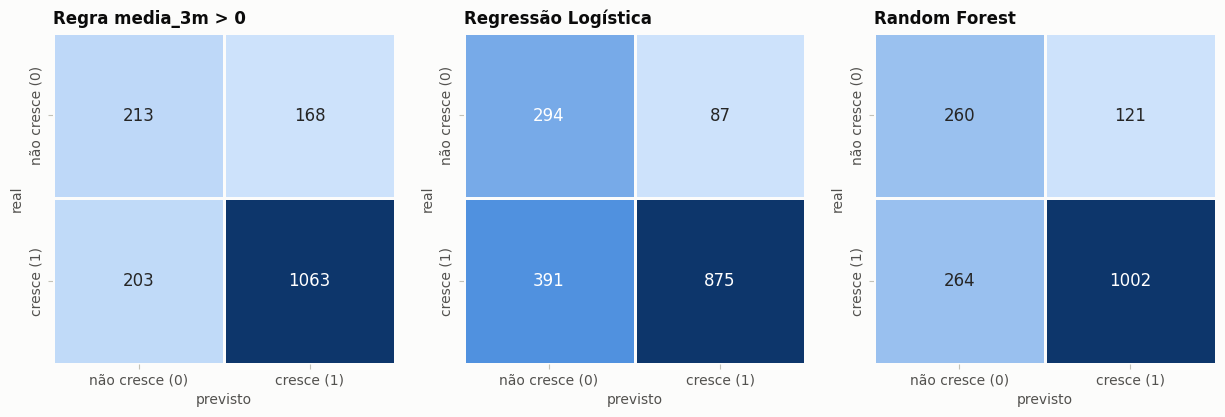

Regra media_3m > 0     VP=1063  FP= 168  VN= 213  FN= 203  | acerto nas quedas (VN/(VN+FP)) = 55.9%
Regressão Logística    VP= 875  FP=  87  VN= 294  FN= 391  | acerto nas quedas (VN/(VN+FP)) = 77.2%
Random Forest          VP=1002  FP= 121  VN= 260  FN= 264  | acerto nas quedas (VN/(VN+FP)) = 68.2%


In [29]:
ROTULOS = ["não cresce (0)", "cresce (1)"]
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, nome in zip(eixos, ["Regra media_3m > 0", "Regressão Logística", "Random Forest"]):
    matriz = confusion_matrix(y_teste, previstos[nome])
    sns.heatmap(matriz, annot=True, fmt="d", cmap=SEQUENCIAL, cbar=False, linewidths=2, linecolor=FUNDO,
                xticklabels=ROTULOS, yticklabels=ROTULOS, annot_kws={"fontsize": 12}, ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
    ax.grid(False)
salvar(fig, "08_matrizes_confusao.png")

for nome in ["Regra media_3m > 0", "Regressão Logística", "Random Forest"]:
    vn, fp, fn, vp = confusion_matrix(y_teste, previstos[nome]).ravel()
    print(f"{nome:22s} VP={vp:4d}  FP={fp:4d}  VN={vn:4d}  FN={fn:4d}  | "
          f"acerto nas quedas (VN/(VN+FP)) = {vn / (vn + fp):.1%}")

### 5.3 Curva ROC

Cada curva mostra, para todos os limites de decisão possíveis, quantos casos de alta o modelo pega (eixo vertical)
contra quantos alarmes falsos ele dá (eixo horizontal). Quanto mais para o canto superior esquerdo, melhor.

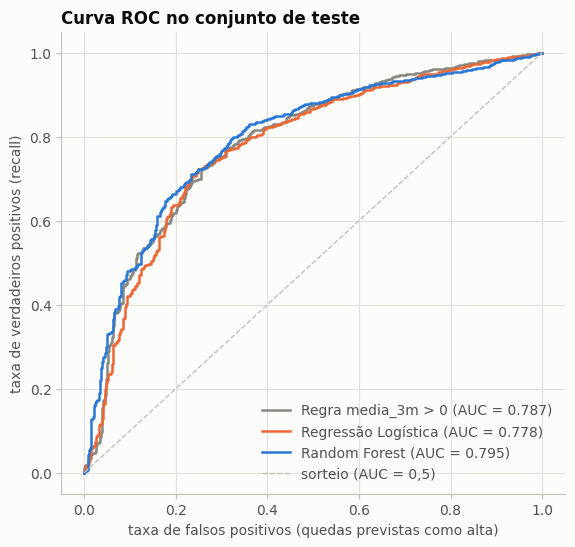

In [30]:
fig, ax = plt.subplots(figsize=(6.5, 6))
curvas = [("Regra media_3m > 0", teste["media_3m"], CINZA), ("Regressão Logística", probabilidades["Regressão Logística"], LARANJA),
          ("Random Forest", probabilidades["Random Forest"], AZUL)]
for nome, pontuacao, cor in curvas:
    fpr, tpr, _ = roc_curve(y_teste, pontuacao)
    ax.plot(fpr, tpr, color=cor, label=f"{nome} (AUC = {roc_auc_score(y_teste, pontuacao):.3f})")
ax.plot([0, 1], [0, 1], color=EIXO, linewidth=1, linestyle="--", label="sorteio (AUC = 0,5)")
ax.set_xlabel("taxa de falsos positivos (quedas previstas como alta)")
ax.set_ylabel("taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend(loc="lower right")
salvar(fig, "09_curva_roc.png")

### 5.4 O que pesa na decisão

À esquerda, a importância de cada atributo no Random Forest (quanto ele ajuda a separar as classes nas árvores). À
direita, os pesos da Regressão Logística com os atributos padronizados: azul aumenta a chance de alta, vermelho
diminui; o tamanho mostra o efeito de um desvio-padrão a mais no atributo.

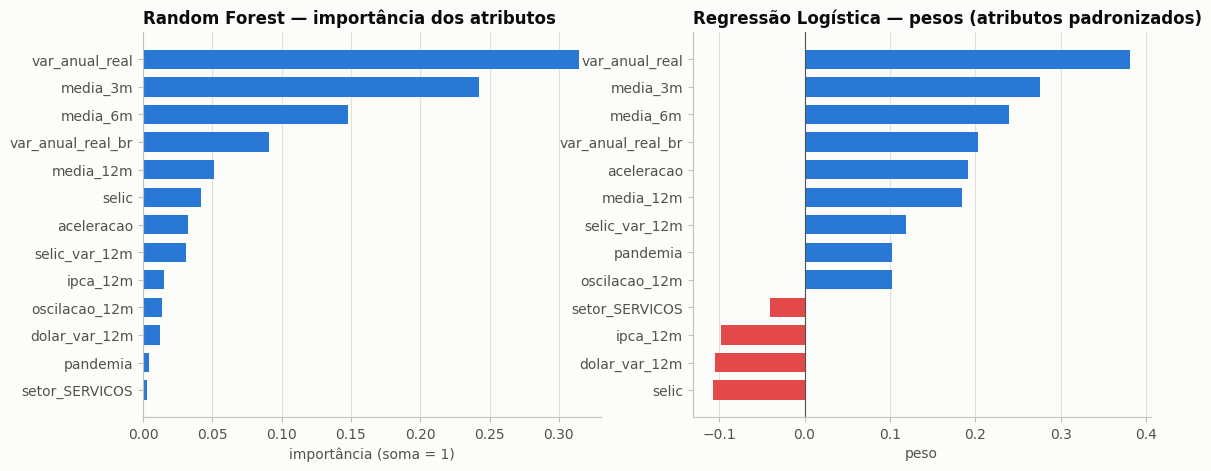

                   importância RF  peso RL
var_anual_real              0.315    0.381
media_3m                    0.242    0.276
media_6m                    0.148    0.240
var_anual_real_br           0.091    0.203
media_12m                   0.051    0.184
selic                       0.042   -0.107
aceleracao                  0.032    0.192
selic_var_12m               0.031    0.119
ipca_12m                    0.015   -0.098
oscilacao_12m               0.014    0.103
dolar_var_12m               0.012   -0.105
pandemia                    0.005    0.103
setor_SERVICOS              0.003   -0.040


In [31]:
def nomes_atributos(pipeline):
    return [n.split("__")[1] for n in pipeline.named_steps["preparo"].get_feature_names_out()]


rf = busca_rf.best_estimator_
importancia = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nomes_atributos(rf)).sort_values()
lr = busca_lr.best_estimator_
pesos = pd.Series(lr.named_steps["modelo"].coef_[0], index=nomes_atributos(lr)).sort_values()

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
eixos[0].barh(importancia.index, importancia.values, color=AZUL, height=0.7)
eixos[0].set_title("Random Forest — importância dos atributos")
eixos[0].set_xlabel("importância (soma = 1)")
eixos[1].barh(pesos.index, pesos.values, color=[AZUL if v > 0 else VERMELHO for v in pesos.values], height=0.7)
eixos[1].axvline(0, color=TEXTO_2, linewidth=0.8)
eixos[1].set_title("Regressão Logística — pesos (atributos padronizados)")
eixos[1].set_xlabel("peso")
for ax in eixos:
    ax.grid(axis="y", visible=False)
salvar(fig, "10_importancia_atributos.png")

print(pd.DataFrame({"importância RF": importancia, "peso RL": pesos}).sort_values("importância RF", ascending=False)
      .round(3).to_string())

**Leitura:** os dois modelos concordam no principal. O que mais pesa é a **tendência recente do próprio estado**
(`var_anual_real`, `media_3m`, `media_6m`) e o **setor no Brasil**. Na Regressão Logística, **Selic alta, dólar
subindo e inflação alta diminuem** a chance de crescimento real — o sinal esperado, já que encarecem o crédito e os
produtos. O peso positivo de `pandemia` reflete a recuperação de 2021, quando quase todos os estados cresceram contra
a base fraca de 2020.

### 5.5 Onde o modelo erra

Acerto do Random Forest por estado (os dois setores juntos) e por ano. A expectativa da fase 2 era errar mais nos
estados mais instáveis (AP, TO, MT, PB, RO).

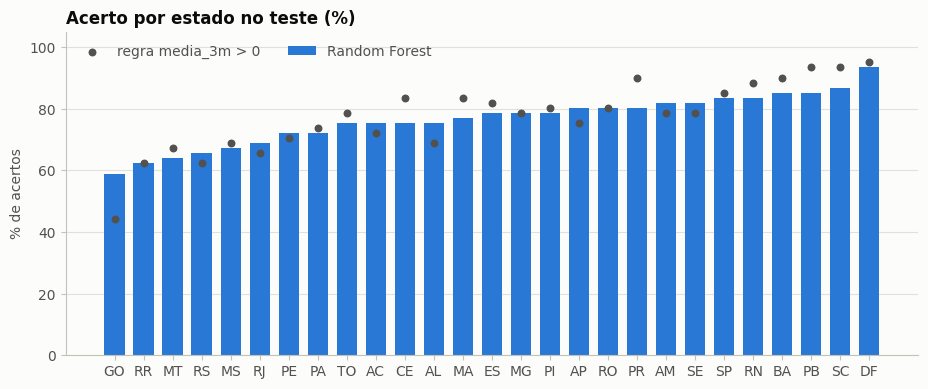

correlação entre acerto do Random Forest e oscilação média do estado: r = -0.16
piores estados: GO 59%, RR 62%, MT 64%, RS 66%, MS 67%
melhores estados: RN 84%, BA 85%, PB 85%, SC 87%, DF 93%


In [32]:
avaliacao = teste[["setor", "uf", "ano", "oscilacao_12m"]].assign(
    real=y_teste.to_numpy(), rf=previstos["Random Forest"], regra=previstos["Regra media_3m > 0"],
)
avaliacao["acertou_rf"] = avaliacao["real"] == avaliacao["rf"]
avaliacao["acertou_regra"] = avaliacao["real"] == avaliacao["regra"]

por_uf = avaliacao.groupby("uf").agg(acerto_rf=("acertou_rf", "mean"), acerto_regra=("acertou_regra", "mean"),
                                     oscilacao_media=("oscilacao_12m", "mean")).sort_values("acerto_rf")
r = por_uf["acerto_rf"].corr(por_uf["oscilacao_media"])

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(por_uf.index, por_uf["acerto_rf"] * 100, color=AZUL, width=0.7, label="Random Forest")
ax.scatter(por_uf.index, por_uf["acerto_regra"] * 100, color=TEXTO_2, s=22, zorder=3, label="regra media_3m > 0")
ax.set_ylim(0, 100)
ax.set_title("Acerto por estado no teste (%)")
ax.set_ylabel("% de acertos")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", ncols=2)
ax.grid(axis="x", visible=False)
salvar(fig, "11_acerto_por_estado.png")

print(f"correlação entre acerto do Random Forest e oscilação média do estado: r = {r:.2f}")
print("piores estados:", ", ".join(f"{uf} {v:.0%}" for uf, v in por_uf["acerto_rf"].head(5).items()))
print("melhores estados:", ", ".join(f"{uf} {v:.0%}" for uf, v in por_uf["acerto_rf"].tail(5).items()))

In [33]:
por_ano_teste = avaliacao.groupby("ano").apply(lambda d: pd.Series({
    "linhas": len(d),
    "% de alta": d["real"].mean() * 100,
    "acurácia bal. Random Forest": balanced_accuracy_score(d["real"], d["rf"]) if d["real"].nunique() > 1 else np.nan,
    "acurácia bal. regra": balanced_accuracy_score(d["real"], d["regra"]) if d["real"].nunique() > 1 else np.nan,
}), include_groups=False)
por_ano_teste.round(3)

,linhas,% de alta,acurácia bal. Random Forest,acurácia bal. regra
ano,,,,
2023,162.0,83.951,0.626,0.629
2024,648.0,84.568,0.766,0.757
2025,648.0,68.673,0.723,0.671
2026,189.0,72.487,0.740,0.704


**Leitura:** a expectativa se confirmou só em parte — a correlação entre acerto e oscilação do estado é fraca
(r ≈ −0,16). MT e RR estão entre os piores, mas GO, RS e MS também. Por ano, o ganho do Random Forest sobre a regra
aparece principalmente em **2025**, quando a proporção de altas caiu (de 85% para 69%): é quando a tendência recente
deixa de valer que os outros atributos fazem diferença.

### 5.6 Respostas às perguntas de negócio

Os números abaixo se referem à execução salva neste notebook (podem variar na terceira casa decimal com outra versão
do scikit-learn).

**O modelo funcionou?** Sim, com ganho modesto. O **Random Forest** teve a melhor acurácia balanceada (≈0,74 contra
≈0,70 da regra simples e ≈0,73 da Regressão Logística) e o melhor ROC-AUC (≈0,80). Ele acerta cerca de 68% das
quedas, contra 56% da regra, e quando diz "vai crescer" acerta quase 9 em cada 10 vezes. A regra tem F1 e recall
maiores porque responde "vai crescer" com mais facilidade — num período com 77% de altas isso parece bom, mas é o
mesmo efeito que dá F1 de 0,87 ao chute "sempre alta". A Regressão Logística é a mais cautelosa: maior precisão e
maior acerto nas quedas, mas perde muitos casos de alta (recall ≈0,69).

**Os resultados fazem sentido?** Sim. Os atributos que mais pesam são a tendência recente do estado e do setor no
Brasil; Selic, dólar e inflação entram com o sinal esperado (juros e dólar altos diminuem a chance de crescimento),
mas pesam menos, coerente com as correlações moderadas vistas na fase 2. Tirar a pandemia do treino piorou os
modelos, o que mostra que os meses de crise ensinam algo útil.

**O modelo gera valor?** Gera um valor prático: separa melhor os casos de queda — onde está o risco para quem investe
ou concede crédito — e entrega uma **probabilidade**, que permite ordenar os estados em vez de só dizer sim ou não.
O ganho aparece justamente quando o cenário muda (2025). O limite é claro: a tendência dos últimos meses já explica
boa parte do futuro, e o modelo melhora essa leitura, não a substitui.

---
## 6. Implantação

### 6.1 Modelo final e ranking

Com o modelo e os parâmetros escolhidos, o **Random Forest final** é re-treinado com **todos os meses que já têm alvo**
(treino + validação + teste), para aprender também com 2024–2026. Ele então responde as linhas de **previsão** — os
meses mais recentes, cujo futuro ainda não aconteceu. Para cada estado e setor, usa-se o último mês publicado.

In [34]:
com_alvo = modelo[modelo["conjunto"] != "previsao"]
modelo_final = clone(busca_rf.best_estimator_)
modelo_final.fit(com_alvo[ATRIBUTOS_MODELO], com_alvo["alvo"].astype(int))

MESES_ABREV = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def janela_prevista(periodo):
    """202606 -> 'jul–set/2026' (os 3 meses seguintes ao mês da linha)"""
    ano, mes = divmod(periodo, 100)
    inicio = pd.Timestamp(year=ano, month=mes, day=1) + pd.DateOffset(months=1)
    fim = inicio + pd.DateOffset(months=2)
    return f"{MESES_ABREV[inicio.month - 1]}–{MESES_ABREV[fim.month - 1]}/{fim.year}"


ultimos = previsao.sort_values("periodo").groupby(CHAVE).tail(1).copy()
ultimos["probabilidade_alta"] = modelo_final.predict_proba(ultimos[ATRIBUTOS_MODELO])[:, 1]
ultimos["previsao"] = np.where(ultimos["probabilidade_alta"] >= 0.5, "cresce", "não cresce")
ultimos["mes_base"] = ultimos["periodo"].map(lambda p: f"{MESES_ABREV[p % 100 - 1]}/{p // 100}")
ultimos["meses_previstos"] = ultimos["periodo"].map(janela_prevista)

ranking = (ultimos.sort_values(["setor", "probabilidade_alta"], ascending=[True, False])
           [["setor", "uf", "mes_base", "meses_previstos", "probabilidade_alta", "previsao", "var_anual_real", "media_3m"]]
           .reset_index(drop=True))
ranking["probabilidade_alta"] = ranking["probabilidade_alta"].round(3)
ranking[["var_anual_real", "media_3m"]] = ranking[["var_anual_real", "media_3m"]].round(2)
ranking.to_csv(PASTA_SAIDAS / "ranking_previsao.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

for setor in NOME_SETOR:
    parte = ranking[ranking["setor"] == setor]
    print(f"{NOME_SETOR[setor]} ({parte['meses_previstos'].iloc[0]}): "
          f"{(parte['previsao'] == 'cresce').sum()} de {len(parte)} estados com previsão de crescimento real")
ranking.groupby("setor").head(5)

Comércio varejista (jul–set/2026): 24 de 27 estados com previsão de crescimento real
Serviços (ago–out/2026): 24 de 27 estados com previsão de crescimento real


,setor,uf,mes_base,meses_previstos,probabilidade_alta,previsao,var_anual_real,media_3m
0,COMERCIO_VAREJISTA,DF,jun/2026,jul–set/2026,0.882,cresce,7.18,5.35
1,COMERCIO_VAREJISTA,PE,jun/2026,jul–set/2026,0.882,cresce,10.36,9.43
2,COMERCIO_VAREJISTA,TO,jun/2026,jul–set/2026,0.866,cresce,8.92,9.23
3,COMERCIO_VAREJISTA,AC,jun/2026,jul–set/2026,0.862,cresce,6.42,3.66
4,COMERCIO_VAREJISTA,BA,jun/2026,jul–set/2026,0.838,cresce,7.17,3.47
27,SERVICOS,SE,jul/2026,ago–out/2026,0.888,cresce,6.73,7.92
28,SERVICOS,AP,jul/2026,ago–out/2026,0.886,cresce,15.03,13.18
29,SERVICOS,RN,jul/2026,ago–out/2026,0.883,cresce,11.24,4.70
30,SERVICOS,DF,jul/2026,ago–out/2026,0.880,cresce,7.55,8.02
31,SERVICOS,BA,jul/2026,ago–out/2026,0.880,cresce,12.25,10.71


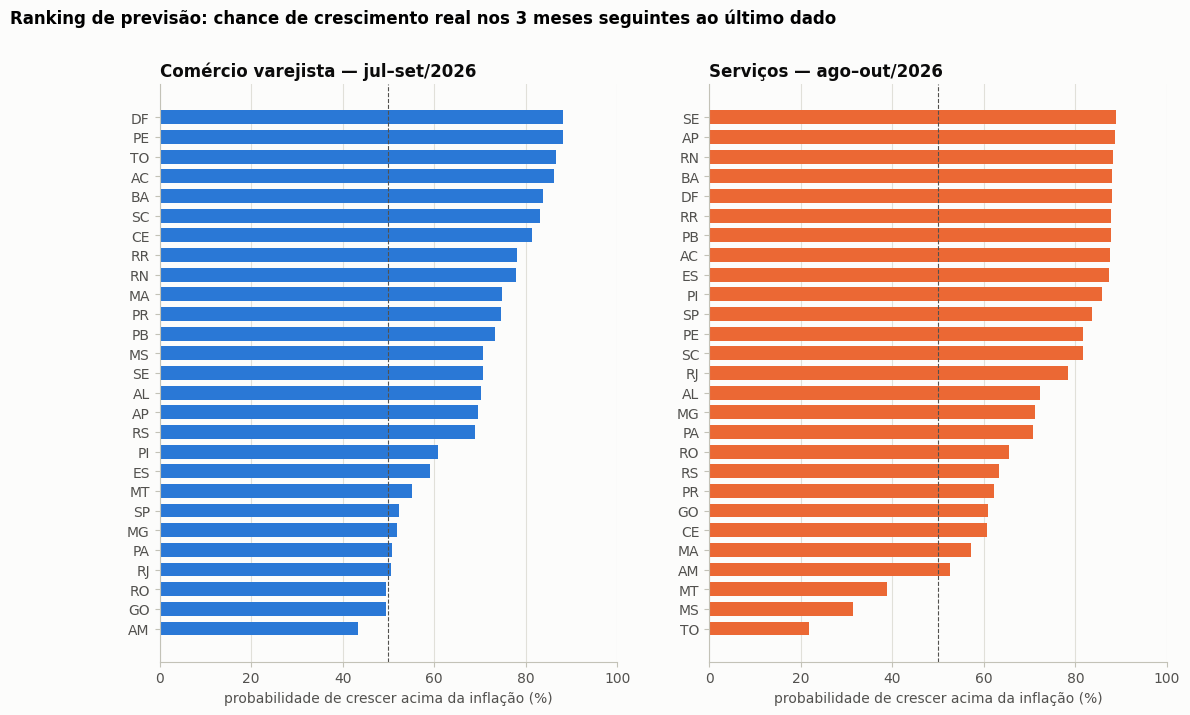

In [35]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 7.5), sharex=True)
for ax, setor in zip(eixos, NOME_SETOR):
    parte = ranking[ranking["setor"] == setor].sort_values("probabilidade_alta")
    ax.barh(parte["uf"], parte["probabilidade_alta"] * 100, color=COR_SETOR[setor], height=0.7)
    ax.axvline(50, color=TEXTO_2, linewidth=0.8, linestyle="--")
    ax.set_title(f"{NOME_SETOR[setor]} — {parte['meses_previstos'].iloc[0]}")
    ax.set_xlim(0, 100)
    ax.set_xlabel("probabilidade de crescer acima da inflação (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Ranking de previsão: chance de crescimento real nos 3 meses seguintes ao último dado",
             x=0.01, ha="left", fontweight="bold")
salvar(fig, "12_ranking_previsao.png")

### 6.2 Disponibilização

O modelo final é salvo com `joblib`. A pasta `api/` do repositório tem uma API em **FastAPI** que carrega esse
arquivo e o ranking e responde, por exemplo:

| Endereço | O que devolve |
|---|---|
| `GET /ranking?setor=varejo` | estados ordenados pela probabilidade de crescimento real |
| `GET /previsoes/PR` | a previsão do Paraná nos dois setores |
| `POST /prever` | a probabilidade para um conjunto de atributos enviado pelo usuário |

**Como seria usado no negócio:** todo mês, quando o IBGE publica um novo mês, roda-se a coleta (`coleta/`), este
notebook e a API passa a responder com o ranking atualizado. Um banco ou uma rede de lojas consultaria o ranking
para priorizar estados na expansão, no crédito ou no estoque, sempre como **probabilidade**, não como certeza.

In [36]:
joblib.dump(modelo_final, PASTA_SAIDAS / "modelo_final.joblib")
print("salvo:", PASTA_SAIDAS / "modelo_final.joblib")
print("parâmetros do modelo final:", {k.split("__")[1]: v for k, v in busca_rf.best_params_.items()})
print("arquivos em saidas/:", sorted(p.name for p in PASTA_SAIDAS.iterdir()))

salvo: /content/trabalho_min_dados/saidas/modelo_final.joblib
parâmetros do modelo final: {'class_weight': None, 'max_depth': 4, 'min_samples_leaf': 1}
arquivos em saidas/: ['dataset_modelo.csv', 'graficos', 'metricas_teste.csv', 'modelo_final.joblib', 'ranking_previsao.csv']


---
## 7. Conclusão

- **Processo completo:** dos dados brutos de 5 fontes oficiais a um ranking de previsão, passando por limpeza,
  integração, transformação sem vazamento do futuro, tratamento de faltantes e divisão no tempo.
- **Resultado:** o Random Forest supera a regra simples e a Regressão Logística na acurácia balanceada e no ROC-AUC,
  com precisão próxima de 90% e acerto nas quedas bem maior que o da regra. O ganho é modesto: a tendência recente
  já carrega boa parte da informação, e o modelo ajuda mais quando o cenário muda.
- **Ranking:** com os dados coletados em 14/09/2026, 24 dos 27 estados aparecem com probabilidade acima de 50% de
  crescimento real nos dois setores; a tabela completa está em `saidas/ranking_previsao.csv`.
- **Limitações:** o dado é um índice (não R$) e cobre empresas formais com 20+ pessoas ocupadas; IPCA, dólar e Selic
  são nacionais; o período de teste (2024–2026) foi de crescimento, então o modelo foi pouco testado em crise.
- **Trabalhos futuros:** testar modelos de *boosting* (ex.: Gradient Boosting), ajustar o limite de decisão para o
  custo de cada erro, avaliar em janelas móveis (re-treino mês a mês) e incluir atributos regionais (emprego, crédito
  por estado).